# Lab 8.1 Epipolar Geometry

In this lab you will estimate the fundamental matrix between two images and display the epipolar lines induced by the fundamental matrix.  The fundamental matrix encodes the relative pose and intrinsics of the two images into a $3\times3$ matrix.  For a given point in the first image, the epipolar line shows where the corresponding point in the second image could be.

In [19]:
import matplotlib.pyplot as plt

import numpy as np
import imageio.v3 as iio
import skimage
from skimage.color import rgb2gray
from skimage.feature import match_descriptors, SIFT
from skimage.feature import plot_matched_features
from skimage.transform import rescale

import cv2

In [20]:
def plot_line(ax,H,W,p):
    """Plot a line in an image of size HxW given the line parameters p = [a,b,c]"""
    a,b,c = p
    if np.abs(b) > np.abs(a):
        # y = (-c - ax)/b
        x = np.arange(W)
        y = (-c - a*x)/b
    else:
        # x = (-c - by)/a
        y = np.arange(H)
        x = (-c - b*y)/a
    ax.plot(x,y)

In [21]:
!wget -nc -q -O kitchen1.jpeg "https://www.dropbox.com/scl/fi/avpf1rrsxd672aujnsg7t/kitchen1.jpeg?rlkey=hhpgiec3hag7zzsa4k5tc9ng7&dl=1"
!wget -nc -q -O kitchen2.jpeg "https://www.dropbox.com/scl/fi/3umydafg5o87r12ucrqdc/kitchen2.jpeg?rlkey=9pggqu4x1zqp2ff11slah6exf&dl=1"

In [22]:
img1 = rescale(iio.imread("kitchen1.jpeg"), 0.25, channel_axis=-1)
img2 = rescale(iio.imread("kitchen2.jpeg"), 0.25, channel_axis=-1)
gray1 = rgb2gray(img1)
gray2 = rgb2gray(img2)

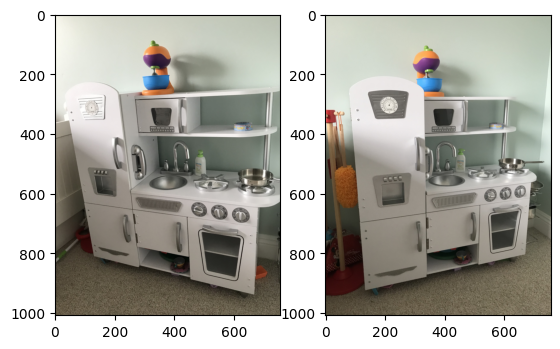

In [23]:
fig, axes = plt.subplots(1,2)
axes[0].imshow(img1)
axes[1].imshow(img2)

Match features from image 1 to 2:

In [24]:
descriptor_extractor = SIFT()

In [25]:
descriptor_extractor.detect_and_extract(gray1)
keypoints1 = descriptor_extractor.keypoints
descriptors1 = descriptor_extractor.descriptors

In [26]:
descriptor_extractor.detect_and_extract(gray2)
keypoints2 = descriptor_extractor.keypoints
descriptors2 = descriptor_extractor.descriptors

In [27]:
matches12 = match_descriptors(
    descriptors1, descriptors2, max_ratio=0.7, cross_check=False
)

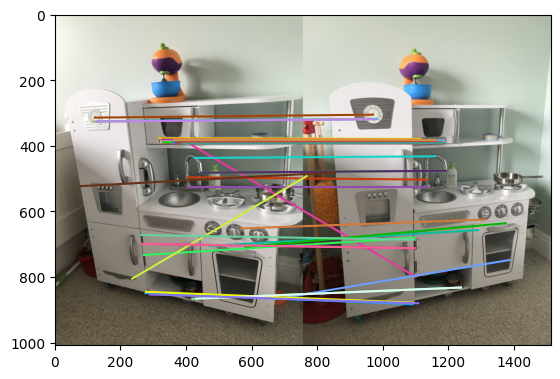

In [28]:
fig,ax = plt.subplots()
plot_matched_features(img1, img2, keypoints0=keypoints1, keypoints1=keypoints2, matches=matches12, ax=ax, only_matches=True)

## Exercises

1. Estimate the fundamental matrix using the OpenCV function `cv2.findFundamentalMat`.  Use the RANSAC method (`cv2.FM_RANSAC`), and an inlier threshold of 3 pixels.

Use `plot_matched_features` to show only the inlier feature matches.

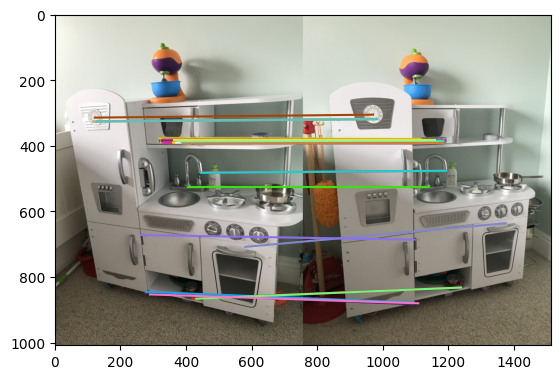

In [29]:
points1 = keypoints1[matches12[:, 0]][:, ::-1].astype(np.float32)
points2 = keypoints2[matches12[:, 1]][:, ::-1].astype(np.float32)

fundamental_matrix, inlier_mask = cv2.findFundamentalMat(
    points1,
    points2,
    cv2.FM_RANSAC,
    ransacReprojThreshold=3
)
inlier_matches = matches12[inlier_mask.ravel().astype(bool)]

# Plot the matched features
fig,ax = plt.subplots()
plot_matched_features(img1, img2, keypoints0=keypoints1, keypoints1=keypoints2, matches=inlier_matches, ax=ax, only_matches=True)

2. Display the epipolar line on the second image for each inlier point in the first image, using the `plot_line` function provided above.  Plot the inlier points in the second image on top.  If everything is computed correctly, the points should intersect the epipolar lines.

Note that for a point $x_1,y_1$ in the first image, the epipolar line in the second image is $l = F \begin{bmatrix}x\\y\\1\end{bmatrix}$.  In NumPy, the matrix multiplication operator is `@`.



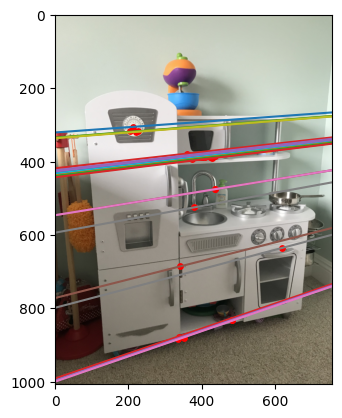

In [30]:
# Matched inlier locations in image 1 and image 2.
points1_inliers = points1[inlier_mask.ravel().astype(bool)]
points2_inliers = points2[inlier_mask.ravel().astype(bool)]

fig, ax = plt.subplots()
ax.imshow(img2)

# For each point in the first image, calculate the epipolar lines in image 2
H, W = img2.shape[:2]
for point1 in points1_inliers:
    x, y = point1
    line = fundamental_matrix @ np.array([x, y, 1])
    plot_line(ax, H, W, line)

# Plot all of the inlier points
ax.scatter(
    points2_inliers[:, 0],  # x / column
    points2_inliers[:, 1],  # y / row
    c="red",
    s=15)